# <a href="https://girafe.ai/" target="_blank" rel="noopener noreferrer"><img src="https://raw.githubusercontent.com/girafe-ai/ml-course/7096a5df4cada5ee651be1e3215c2f7fb8a7e0bf/logo_margin.svg" alt="girafe-ai logo" width="150px" align="left"></a> YMLS Uzbekistan, ML Fundamentals, fall 2026 <a class="tocSkip">

# Week 1, seminar 2: kNN practice

k-nearest neighbours in scikit-learn: decision boundaries for different `k`, distance metrics and weights, a NumPy warm-up for HW1, kNN regression, the curse of dimensionality, and scaling and model selection on the Wine dataset.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/girafe-ai/ml-course/blob/26f_ymls_uz/week0_01_intro_and_knn/week0_01_02_knn_practice__completed.ipynb)

This week's [lecture slides](https://github.com/girafe-ai/ml-course/blob/26f_ymls_uz/week0_01_intro_and_knn/ml-basic_lect01_intro_knn.pdf) and [interactive pages](https://raw.githack.com/girafe-ai/ml-course/26f_ymls_uz/week0_01_intro_and_knn/interactive/index.html) (`interactive/index.html`) are in the same folder.

_YMLS Uzbekistan, ML Fundamentals, fall 2026_

_Completed version with solutions and outputs. The student version is `week0_01_02_knn_practice.ipynb`._

## sklearn.neighbors

The [user guide](https://scikit-learn.org/stable/modules/neighbors.html) and the [API reference](https://scikit-learn.org/stable/api/sklearn.neighbors.html).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from sklearn import datasets
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
    validation_curve,
)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler


SEED = 42

# Plot style: gray axes, colour only for data
INK, INK2, INK3, LINE = "#1D1D1F", "#6E6E73", "#86868B", "#D2D2D7"
ACCENT = "#0071E3"
CLASS_COLORS = ["#0071E3", "#FF9F0A", "#34C759"]  # classes 0, 1, 2
MARKERS = ["o", "s", "^"]  # every class also gets its own marker
SPLIT_COLORS = {"train": "#0071E3", "val": "#FF9F0A", "test": "#AF52DE"}
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 13,
        "axes.edgecolor": LINE,
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
        "axes.prop_cycle": plt.cycler(color=CLASS_COLORS + [SPLIT_COLORS["test"], INK3]),
        "xtick.color": INK3,
        "ytick.color": INK3,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "xtick.major.size": 0,
        "ytick.major.size": 0,
        "legend.frameon": False,
        "legend.fontsize": 11,
        "lines.linewidth": 2.2,
        "lines.markersize": 6,
        "figure.facecolor": "white",
    }
)

REGION_COLORS = ["#DCEBFB", "#FFEFD6", "#DDF4E2"]  # class colours at about 15% on white
CMAP_REGIONS = ListedColormap(REGION_COLORS)
TRAIN_COLOR, VAL_COLOR, TEST_COLOR = SPLIT_COLORS.values()

## A toy task with 2 features

In [2]:
X_toy, y_toy = datasets.make_classification(
    n_samples=100,
    n_features=2,
    n_informative=2,
    n_classes=3,
    n_redundant=0,
    n_clusters_per_class=1,
    random_state=3,
)

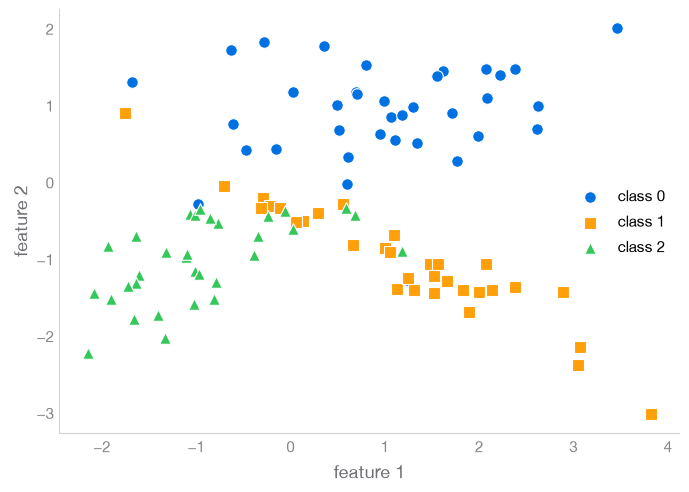

In [3]:
def plot_dataset(X, y, ax=None, s=70):
    """Scatter plot of a 2D dataset: one colour and one marker per class."""
    ax = ax or plt.gca()
    for label in np.unique(y):
        mask = y == label
        ax.scatter(
            X[mask, 0],
            X[mask, 1],
            color=CLASS_COLORS[label],
            marker=MARKERS[label],
            s=s,
            edgecolor="white",
            linewidth=0.8,
            label=f"class {label}",
        )
    ax.set(xlabel="feature 1", ylabel="feature 2")
    ax.legend()
    return ax


fig, ax = plt.subplots(figsize=(8, 5.5))
plot_dataset(X_toy, y_toy, ax=ax)
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X_toy, y_toy, test_size=0.3, random_state=1)
print(X_train.shape, X_test.shape)

(70, 2) (30, 2)


## Fit the model

In [5]:
clf = KNeighborsClassifier()  # n_neighbors=5 by default
clf.fit(X_train, y_train)  # "training" = memorizing X_train and y_train
print(clf)

KNeighborsClassifier()


In [6]:
predictions = clf.predict(X_test)
accuracy_score(y_test, predictions)

0.9

In [7]:
predictions

array([0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 2, 2, 2, 2, 2, 1, 1, 1, 1, 2, 2, 0,
       2, 0, 0, 0, 1, 1, 2, 0])

### Decision surface

Predict a class for every point of a fine grid and paint the plane with it. Points with a white edge are training points, points with a dark edge are test points.

In [8]:
def make_meshgrid(data, step=0.05, border=0.5):
    x_min, x_max = data[:, 0].min() - border, data[:, 0].max() + border
    y_min, y_max = data[:, 1].min() - border, data[:, 1].max() + border
    return np.meshgrid(np.arange(x_min, x_max, step), np.arange(y_min, y_max, step))


def plot_decision_surface(estimator, X_train, y_train, X_test, y_test, ax=None, title=None):
    """Fit `estimator` on train, paint its predictions on a grid, show train and test points."""
    ax = ax or plt.gca()
    estimator.fit(X_train, y_train)

    xx, yy = make_meshgrid(np.vstack([X_train, X_test]))
    grid_predictions = estimator.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.pcolormesh(xx, yy, grid_predictions, cmap=CMAP_REGIONS, vmin=0, vmax=len(REGION_COLORS) - 1)

    for label, (color, marker) in enumerate(zip(CLASS_COLORS, MARKERS, strict=True)):
        train_mask, test_mask = y_train == label, y_test == label
        ax.scatter(
            X_train[train_mask, 0],
            X_train[train_mask, 1],
            color=color,
            marker=marker,
            s=45,
            edgecolor="white",
            linewidth=0.7,
        )
        ax.scatter(
            X_test[test_mask, 0],
            X_test[test_mask, 1],
            color=color,
            marker=marker,
            s=70,
            edgecolor=INK,
            linewidth=1.5,
        )

    train_acc = accuracy_score(y_train, estimator.predict(X_train))
    test_acc = accuracy_score(y_test, estimator.predict(X_test))
    ax.set_title(f"{title or estimator}\ntrain {train_acc:.2f}, test {test_acc:.2f}")
    ax.set_xticks([])
    ax.set_yticks([])
    return ax


LEGEND_HANDLES = [
    Line2D([], [], ls="", marker=m, ms=9, color=c, mec="white", label=f"class {i}")
    for i, (c, m) in enumerate(zip(CLASS_COLORS, MARKERS, strict=True))
] + [
    Line2D([], [], ls="", marker="o", ms=9, color=INK3, mec="white", label="train point"),
    Line2D([], [], ls="", marker="o", ms=9, color=INK3, mec=INK, mew=1.5, label="test point"),
]

Decision surfaces for $k \in \{1, 3, 5, 15, 40\}$. The last panel shows train and test accuracy for every $k$ from 1 to 50 (there are 70 training points).

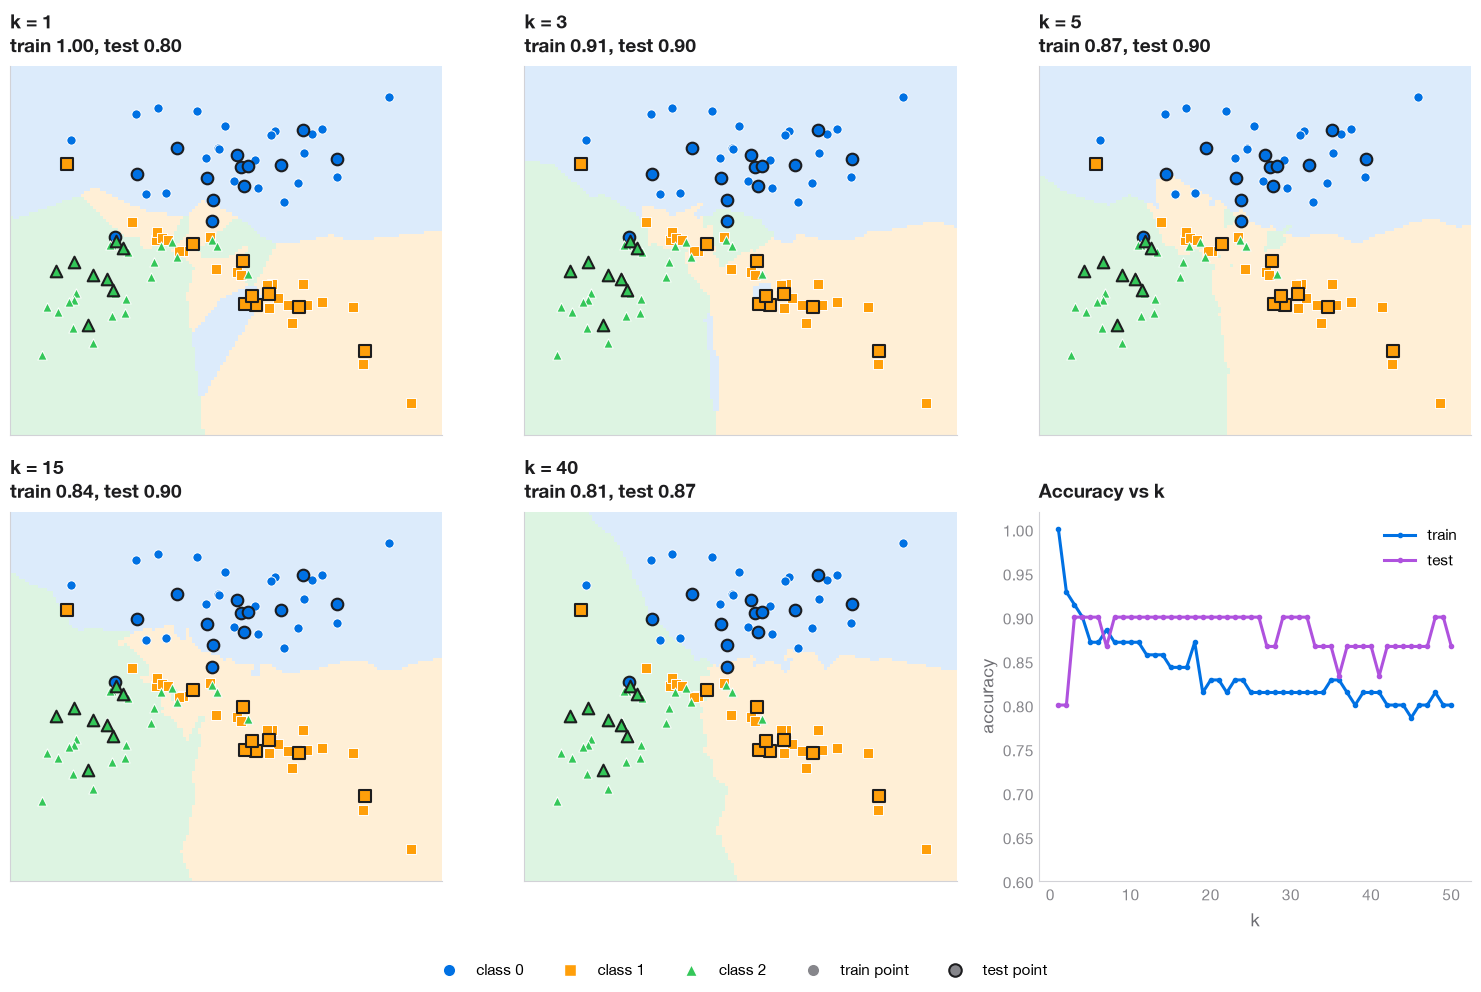

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for k, ax in zip([1, 3, 5, 15, 40], axes.flat[:5], strict=True):
    model = KNeighborsClassifier(n_neighbors=k)
    plot_decision_surface(model, X_train, y_train, X_test, y_test, ax=ax, title=f"k = {k}")

k_range = np.arange(1, 51)
train_acc, test_acc = [], []
for k in k_range:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))
ax = axes.flat[-1]
ax.plot(k_range, train_acc, "o-", ms=3, color=TRAIN_COLOR, label="train")
ax.plot(k_range, test_acc, "o-", ms=3, color=TEST_COLOR, label="test")
ax.set(xlabel="k", ylabel="accuracy", title="Accuracy vs k", ylim=(0.6, 1.02))
ax.legend()

fig.legend(handles=LEGEND_HANDLES, loc="lower center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

- At `k = 1` train accuracy is 100% and the boundary has islands around single points. The model memorizes noise: this is overfitting.
- Larger `k` smooths the boundary. At `k = 40` (of 70 training points) the smaller regions start to wash out: underfitting.
- Train accuracy cannot choose `k`, since it is perfect at `k = 1`. With only 30 test points the test curve is noisy too, so later we use cross-validation.

### Try it

Move the slider and switch the metric and the weights (needs `ipywidgets`; works in Jupyter and Colab). Compare `k = 1` with `k = 50`, and try `metric="cosine"`. On the interactive page `05_knn_playground.html` you can also draw your own points.

In [ ]:
try:
    from ipywidgets import Dropdown, IntSlider, interact
except ImportError:
    print("ipywidgets is not installed: `pip install ipywidgets` to get the interactive plot.")
else:

    def show_knn(k=5, metric="euclidean", weights="uniform"):
        fig, ax = plt.subplots(figsize=(7, 5.5))
        model = KNeighborsClassifier(n_neighbors=k, metric=metric, weights=weights)
        title = f"k = {k}, metric = {metric}, weights = {weights}"
        plot_decision_surface(model, X_train, y_train, X_test, y_test, ax=ax, title=title)
        plt.show()

    interact(
        show_knn,
        k=IntSlider(value=5, min=1, max=50, step=1, continuous_update=False),
        metric=Dropdown(options=["euclidean", "manhattan", "chebyshev", "cosine"]),
        weights=Dropdown(options=["uniform", "distance"]),
    )

## Distance metrics and weights

Common distances for $x, z \in \mathbb{R}^d$:

| `metric` | formula | comment |
|---|---|---|
| `euclidean` ($L_2$) | $\sqrt{\sum_j (x_j - z_j)^2}$ | the default (`minkowski` with `p=2`) |
| `manhattan` ($L_1$) | $\sum_j \lvert x_j - z_j \rvert$ | `minkowski` with `p=1`; less sensitive to one large difference |
| `chebyshev` ($L_\infty$) | $\max_j \lvert x_j - z_j \rvert$ | only the largest coordinate difference counts |
| `cosine` | $1 - \frac{\langle x, z \rangle}{\lVert x \rVert \, \lVert z \rVert}$ | ignores length, only the direction counts; used for texts and embeddings |

With `weights="uniform"` each of the `k` neighbours has one vote. With `weights="distance"` a neighbour at distance $\rho$ gets a vote of $1/\rho$, so closer neighbours count more.

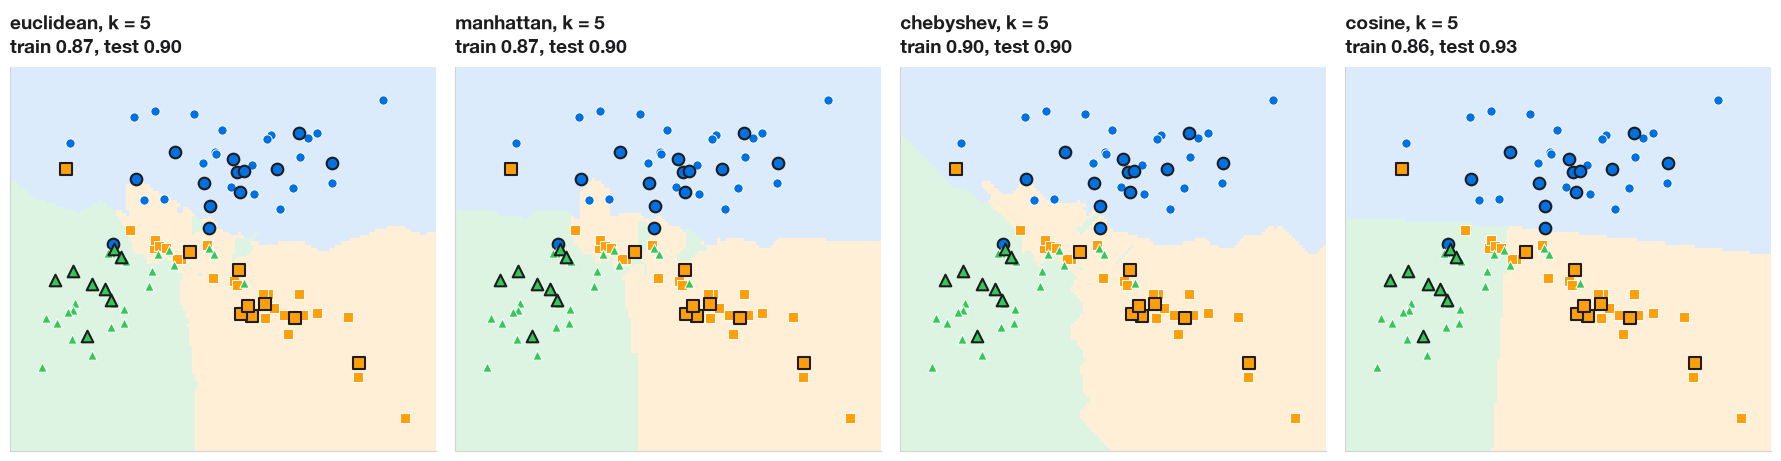

In [10]:
metrics = ["euclidean", "manhattan", "chebyshev", "cosine"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for metric, ax in zip(metrics, axes, strict=True):
    model = KNeighborsClassifier(n_neighbors=5, metric=metric)
    plot_decision_surface(model, X_train, y_train, X_test, y_test, ax=ax, title=f"{metric}, k = 5")
fig.tight_layout()
plt.show()

The first three metrics give similar pictures, with more axis-aligned pieces for `manhattan` and `chebyshev`. The `cosine` regions are wedges from the origin, because cosine distance looks only at the direction of a point.

**Exercise.** Compare all metrics and both weightings with 5-fold cross-validation on the training set (`k = 5`). The helper `cv_accuracy` below wraps `cross_val_score`; we reuse it later.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # reused below


def cv_accuracy(model, X, y):
    """Mean 5-fold cross-validation accuracy of `model` on (X, y)."""
    return cross_val_score(model, X, y, cv=cv, scoring="accuracy").mean()

In [12]:
rows = []
for metric in metrics:
    for weights in ["uniform", "distance"]:
        model = KNeighborsClassifier(n_neighbors=5, metric=metric, weights=weights)
        score = cv_accuracy(model, X_train, y_train)
        rows.append({"metric": metric, "weights": weights, "CV accuracy": score})

metric_table = pd.DataFrame(rows).pivot(index="metric", columns="weights", values="CV accuracy")
metric_table.round(3)

weights,distance,uniform
metric,,
chebyshev,0.843,0.800
cosine,0.743,0.857
euclidean,0.829,0.829
manhattan,0.829,0.829


On 70 points a difference of 0.03 is about two objects, so most entries are within noise. The metric and the weights are hyperparameters like `k`, so choose them by validation. They tend to matter more on real data with many features of different kinds.

## kNN from scratch in NumPy

A warm-up for HW1: a kNN prediction is a few lines of NumPy. Here is one test point (black) and its 5 nearest training neighbours (circled), found by sklearn. Three of them are class 0, so the prediction is class 0.

distances:  [0.461 0.617 0.656 0.688 0.758]
neighbours: [23  4 27 14 29]
their labels: [0 1 2 0 0] -> prediction: [0]


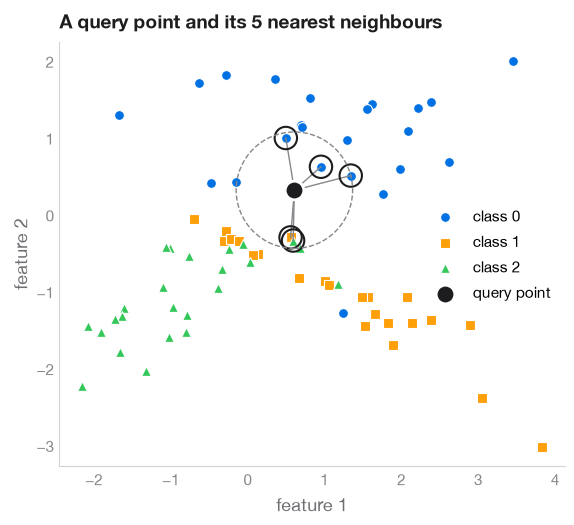

In [13]:
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
query = X_test[21]
distances, neighbours = knn.kneighbors(query.reshape(1, -1))  # both of shape (1, k)

print("distances: ", distances[0].round(3))
print("neighbours:", neighbours[0])
print("their labels:", y_train[neighbours[0]], "-> prediction:", knn.predict(query.reshape(1, -1)))

fig, ax = plt.subplots(figsize=(7, 5.5))
plot_dataset(X_train, y_train, ax=ax, s=50)
for i in neighbours[0]:
    ax.plot(*np.c_[query, X_train[i]], color=INK3, lw=1, zorder=1)
nn_points = X_train[neighbours[0]]
ax.scatter(nn_points[:, 0], nn_points[:, 1], s=260, facecolor="none", edgecolor=INK, lw=1.5)
ax.add_patch(plt.Circle(query, distances[0, -1], fill=False, ls="--", color=INK3))
ax.scatter(*query, s=180, color=INK, edgecolor="white", lw=2, zorder=5, label="query point")
ax.legend()
ax.set_aspect("equal")
ax.set_title("A query point and its 5 nearest neighbours")
plt.show()

**Exercise.** Implement `knn_predict_one`, the prediction for one query point:

1. Distances from `x_query` to every training point. `X_train - x_query` broadcasts, because `X_train` has shape `(n_train, d)` and `x_query` has shape `(d,)`. Then take `np.linalg.norm(..., axis=1)`.
2. Indices of the `k` smallest distances: `np.argsort`.
3. Votes per class: `np.bincount` of the neighbours' labels.
4. The class with the most votes: `argmax`. On a tie it returns the smaller label, as sklearn does.

In [14]:
def knn_predict_one(x_query, X_train, y_train, k=5):
    """Majority vote of the k nearest training points (Euclidean distance) for one query."""
    distances = np.linalg.norm(X_train - x_query, axis=1)  # shape (n_train,)
    nearest = np.argsort(distances, kind="stable")[:k]  # indices of the k closest points
    votes = np.bincount(y_train[nearest], minlength=y_train.max() + 1)  # votes per class
    return votes.argmax()

In [15]:
my_predictions = [knn_predict_one(x, X_train, y_train, k=5) for x in X_test]

if my_predictions[0] is None:
    print("Implement knn_predict_one above first.")
else:
    sklearn_predictions = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train).predict(X_test)
    print("mine:   ", np.array(my_predictions[:10]))
    print("sklearn:", sklearn_predictions[:10])
    assert np.array_equal(my_predictions, sklearn_predictions), "Predictions differ from sklearn"
    print(f"All {len(X_test)} test predictions match sklearn.")

mine:    [0 0 0 1 0 1 1 0 0 0]
sklearn: [0 0 0 1 0 1 1 0 0 0]
All 30 test predictions match sklearn.


In HW1 you write the full version: the matrix of distances between all test and all training points, with two loops, one loop and no loops, and you compare their speed. HW1 does not allow `np.linalg.norm`, so there you write the distance yourself.

## kNN for regression

The prediction is the mean target of the `k` nearest neighbours. A 1D example with noisy $y = \sin x$:

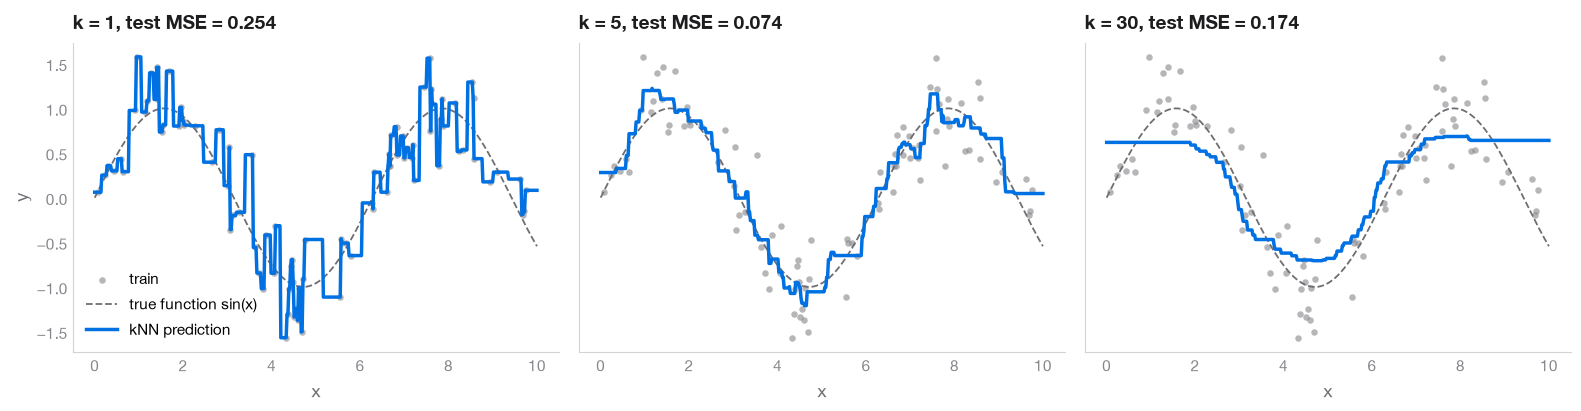

In [16]:
rng = np.random.default_rng(SEED)
x_reg = rng.uniform(0, 10, size=(120, 1))
y_reg = np.sin(x_reg[:, 0]) + rng.normal(scale=0.3, size=120)
x_reg_train, x_reg_test, y_reg_train, y_reg_test = train_test_split(
    x_reg, y_reg, test_size=0.25, random_state=SEED
)
x_plot = np.linspace(0, 10, 500).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for k, ax in zip([1, 5, 30], axes, strict=True):
    reg = KNeighborsRegressor(n_neighbors=k).fit(x_reg_train, y_reg_train)
    mse = mean_squared_error(y_reg_test, reg.predict(x_reg_test))
    ax.scatter(x_reg_train, y_reg_train, s=22, color=INK3, alpha=0.6, lw=0, label="train")
    ax.plot(x_plot, np.sin(x_plot), "--", color=INK2, lw=1.3, label="true function sin(x)")
    ax.plot(x_plot, reg.predict(x_plot), color=ACCENT, lw=2.5, label="kNN prediction")
    ax.set(title=f"k = {k}, test MSE = {mse:.3f}", xlabel="x")
axes[0].set_ylabel("y")
axes[0].legend(loc="lower left")
fig.tight_layout()
plt.show()

`k = 1` passes through every training point, noise included (overfitting). `k = 30` is too flat and misses the peaks (underfitting). The prediction is piecewise constant, because it changes only when the set of neighbours changes. `weights="distance"` makes it less blocky.

## More features

On two features kNN works well. Now a harder problem: 100 objects with 100 features.

In [17]:
X_hard, y_hard = datasets.make_classification(
    n_samples=100,
    n_features=100,
    n_informative=50,
    n_classes=3,
    n_redundant=50,
    n_clusters_per_class=1,
    random_state=42,
)
X_hard_train, X_hard_test, y_hard_train, y_hard_test = train_test_split(
    X_hard, y_hard, test_size=0.3, random_state=1
)

In [18]:
clf = KNeighborsClassifier(n_neighbors=5)
clf.fit(X_hard_train, y_hard_train)

predictions = clf.predict(X_hard_test)
accuracy_score(y_hard_test, predictions)

0.6

## Accuracy vs the number of features

Accuracy is only 0.6. Is it just this dataset? Below, the number of features `d` grows while we keep 1000 objects and 5 classes. Half of the features are informative, the other half are linear combinations of them.

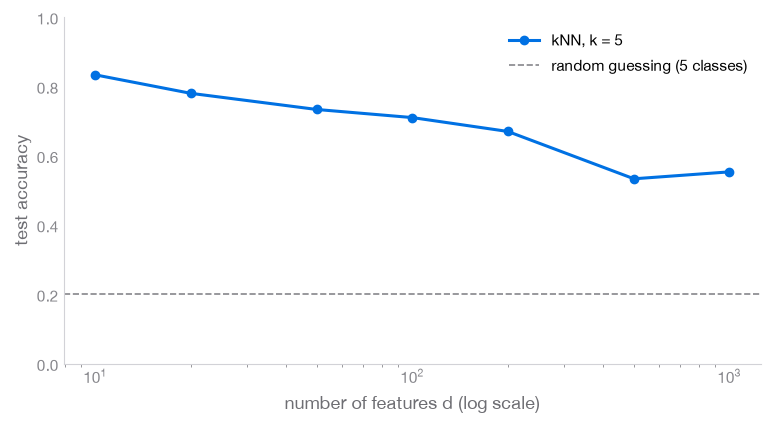

In [19]:
def knn_accuracy_vs_dimension(dimensions, n_classes=5, n_samples=1000, k=5):
    """Test accuracy of kNN on make_classification problems of growing dimension."""
    scores = []
    for dim in dimensions:
        X_dim, y_dim = datasets.make_classification(
            n_samples=n_samples,
            n_features=dim,
            n_informative=dim // 2,
            n_redundant=dim // 2,
            n_classes=n_classes,
            n_clusters_per_class=1,
            random_state=42,
        )
        X_tr, X_te, y_tr, y_te = train_test_split(X_dim, y_dim, test_size=0.3, random_state=1)
        scores.append(KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr).score(X_te, y_te))
    return scores


dimensions = [10, 20, 50, 100, 200, 500, 1000]
scores = knn_accuracy_vs_dimension(dimensions, n_classes=5)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(dimensions, scores, "o-", color=ACCENT, label="kNN, k = 5")
ax.axhline(1 / 5, ls="--", lw=1.2, color=INK3, label="random guessing (5 classes)")
ax.set(xscale="log", xlabel="number of features d (log scale)", ylabel="test accuracy", ylim=(0, 1))
ax.legend()
plt.show()

### Why: distances concentrate

Take 1000 random points in the unit cube $[0, 1]^d$ and a random query point. As $d$ grows, the nearest and the farthest points become almost equally far: the relative contrast $(\rho_{\max} - \rho_{\min}) / \rho_{\min}$ goes to zero. Then "the nearest neighbour" says little. This is the curse of dimensionality (see also the interactive page `08_curse_of_dimensionality.html`).

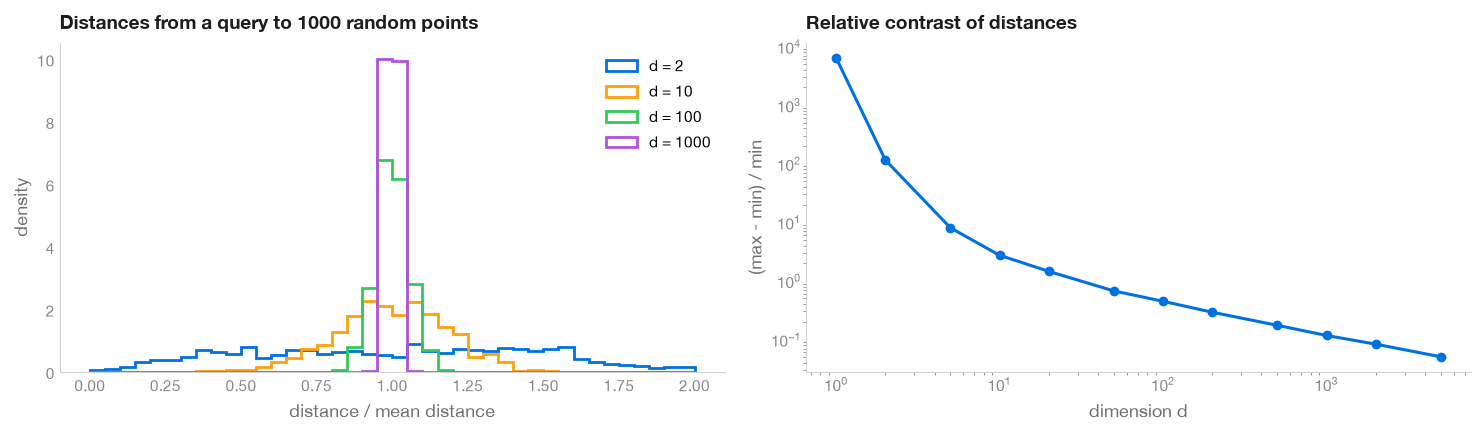

d,1,2,5,10,20,50,100,200,500,1000,2000,5000
(max - min) / min,6411.81,115.696,8.056,2.733,1.453,0.673,0.448,0.291,0.174,0.117,0.083,0.051


In [20]:
rng = np.random.default_rng(SEED)
dims = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000]
contrast, distances_by_dim = [], {}
for dim in dims:
    points = rng.random((1000, dim))
    ratios = []
    for query in rng.random((20, dim)):  # 20 random queries, one at a time
        dist = np.linalg.norm(points - query, axis=1)
        ratios.append((dist.max() - dist.min()) / dist.min())
    contrast.append(np.mean(ratios))
    distances_by_dim[dim] = dist / dist.mean()  # distances of the last query, for the histogram

fig, (ax_hist, ax_ratio) = plt.subplots(1, 2, figsize=(15, 4.5))
hist_colors = [CLASS_COLORS[0], CLASS_COLORS[1], CLASS_COLORS[2], TEST_COLOR]
for dim, color in zip([2, 10, 100, 1000], hist_colors, strict=True):
    ax_hist.hist(
        distances_by_dim[dim],
        bins=40,
        range=(0, 2),
        density=True,
        histtype="step",
        lw=2,
        color=color,
        label=f"d = {dim}",
    )
ax_hist.set(
    xlabel="distance / mean distance",
    ylabel="density",
    title="Distances from a query to 1000 random points",
)
ax_hist.legend()

ax_ratio.plot(dims, contrast, "o-", color=ACCENT)
ax_ratio.set(
    xscale="log",
    yscale="log",
    xlabel="dimension d",
    ylabel="(max - min) / min",
    title="Relative contrast of distances",
)
fig.tight_layout()
plt.show()

pd.Series(contrast, index=pd.Index(dims, name="d"), name="(max - min) / min").round(3).to_frame().T

In 2D the farthest point is about a hundred times farther than the nearest one. In 1000D it is only about 12% farther. Real data usually lies near a low-dimensional structure, which is why kNN still works on image or text embeddings. It needs a good representation and few irrelevant features.

## Real data: Wine

The Wine dataset from `week0_01_01_ml_workflow_and_baseline.ipynb` comes with scikit-learn: 178 wines, 13 chemical features, 3 cultivars.

In [21]:
wine = datasets.load_wine(as_frame=True)
X_wine, y_wine = wine.data, wine.target
X_wine.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [22]:
X_wine_train, X_wine_test, y_wine_train, y_wine_test = train_test_split(
    X_wine, y_wine, test_size=0.2, random_state=42, stratify=y_wine
)

print(X_wine_train.shape)
print(X_wine_test.shape)

(142, 13)
(36, 13)


`X_wine_test` waits for the bonus at the very end. Until then we use cross-validation on `X_wine_train`.

### Feature scaling

kNN compares objects by distance, so the scale of each feature matters. Here are the standard deviations:

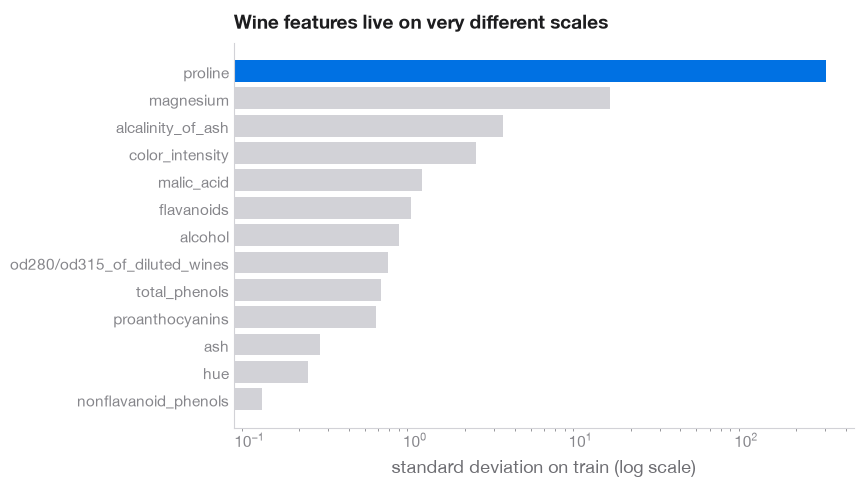

In [23]:
stds = X_wine_train.std().sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
bar_colors = [ACCENT if name == "proline" else LINE for name in stds.index]
ax.barh(stds.index, stds.values, color=bar_colors)
ax.set(
    xscale="log",
    xlabel="standard deviation on train (log scale)",
    title="Wine features live on very different scales",
)
plt.show()

How much of the distance comes from `proline`? For two independent random objects $x_a, x_b$ we have $\mathbb{E}\lVert x_a - x_b \rVert^2 = 2 \sum_{j=1}^{d} \operatorname{Var} x^{(j)}$, so the share of feature $j$ in the squared Euclidean distance is $\operatorname{Var} x^{(j)} / \sum_m \operatorname{Var} x^{(m)}$.

In [24]:
variance_share = X_wine_train.var() / X_wine_train.var().sum()
print(f"share of proline in the squared Euclidean distance: {variance_share['proline']:.1%}")
print(f"share of the other 12 features together:            {1 - variance_share['proline']:.1%}")

share of proline in the squared Euclidean distance: 99.7%
share of the other 12 features together:            0.3%


So kNN on raw Wine features is almost kNN on `proline` alone.

**Exercise.** Compare the 5-fold CV accuracy on `X_wine_train` of `KNeighborsClassifier(n_neighbors=5)` on raw features and of the same model after `StandardScaler` in a pipeline.

In [25]:
raw_cv_acc = cv_accuracy(KNeighborsClassifier(n_neighbors=5), X_wine_train, y_wine_train)
scaled_cv_acc = cv_accuracy(
    make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    X_wine_train,
    y_wine_train,
)

if raw_cv_acc is None or scaled_cv_acc is None:
    print("Fill in the cell above.")
else:
    print(f"raw features:      {raw_cv_acc:.3f}")
    print(f"standardized:      {scaled_cv_acc:.3f}")

raw features:      0.705
standardized:      0.951


### Choosing k with a validation curve

`validation_curve` computes train and cross-validation scores over a range of one hyperparameter. We run it for the scaled pipeline and `k = 1, ..., 40`.

**Exercise.** What is the name of `n_neighbors` inside the pipeline? `make_pipeline` names each step by its class name in lowercase, and parameters are named `<step name>__<parameter>` (two underscores). Check your guess with `scaled_knn.get_params().keys()`.

In [26]:
k_range_wine = np.arange(1, 41)
scaled_knn = make_pipeline(StandardScaler(), KNeighborsClassifier())
param_name = "kneighborsclassifier__n_neighbors"

train_scores = cv_scores = None
if param_name is not None:
    train_scores, cv_scores = validation_curve(
        scaled_knn,
        X_wine_train,
        y_wine_train,
        param_name=param_name,
        param_range=k_range_wine,
        cv=cv,
    )  # both of shape (len(k_range_wine), n_folds)

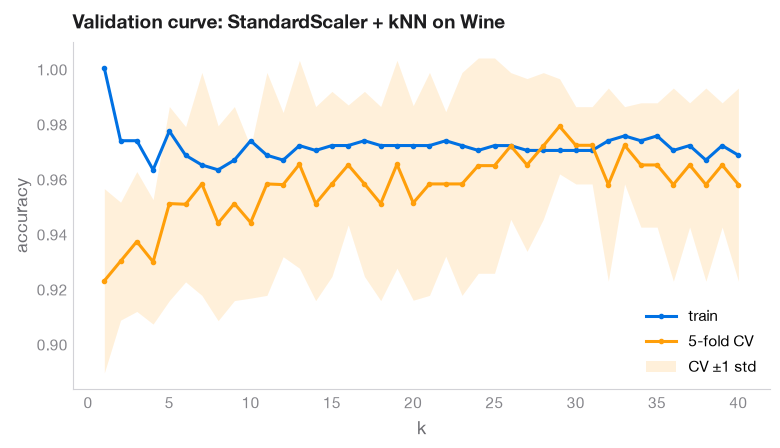

best k by CV: 29, CV accuracy 0.979


In [27]:
if train_scores is None:
    print("Fill in the cell above.")
else:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for scores, color, label in [
        (train_scores, TRAIN_COLOR, "train"),
        (cv_scores, VAL_COLOR, "5-fold CV"),
    ]:
        ax.plot(k_range_wine, scores.mean(axis=1), "o-", ms=3, color=color, label=label)
    cv_mean, cv_std = cv_scores.mean(axis=1), cv_scores.std(axis=1)
    ax.fill_between(
        k_range_wine,
        cv_mean - cv_std,
        cv_mean + cv_std,
        color=VAL_COLOR,
        alpha=0.15,
        lw=0,
        label="CV ±1 std",
    )
    ax.set(xlabel="k", ylabel="accuracy", title="Validation curve: StandardScaler + kNN on Wine")
    ax.legend(loc="lower right")
    plt.show()
    best_k = k_range_wine[cv_scores.mean(axis=1).argmax()]
    print(f"best k by CV: {best_k}, CV accuracy {cv_scores.mean(axis=1).max():.3f}")

Train accuracy is 1.0 at `k = 1`, since every point is its own nearest neighbour, and then drops. CV accuracy grows and then stays on a plateau. The gap between the curves shows overfitting. Any `k` on the plateau, within about one standard deviation of the best, is a reasonable choice.

# Practice

Build the best kNN pipeline for Wine. Try the scaler (`StandardScaler`, `MinMaxScaler`, `RobustScaler`), `n_neighbors`, `weights`, and `metric` or `p` (the Minkowski power: `p=1` is Manhattan, `p=2` is Euclidean). Choose with cross-validation on `X_wine_train` only, for example with `GridSearchCV`. The cell below runs as is: an empty grid tests only the default pipeline. Fill in `param_grid`.

In [28]:
scalers = [StandardScaler(), MinMaxScaler(), RobustScaler()]
pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
param_grid = {
    "scaler": scalers,
    "knn__n_neighbors": list(range(1, 31, 2)),
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}
search = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy")
search.fit(X_wine_train, y_wine_train)

print(f"{len(search.cv_results_['params'])} candidate pipelines")
print("best params:", search.best_params_)
print(f"best CV accuracy: {search.best_score_:.3f}")

180 candidate pipelines
best params: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform', 'scaler': StandardScaler()}
best CV accuracy: 0.979


In [29]:
# The 10 best candidates: many of them are within one std of each other
columns = {"mean_test_score": "CV accuracy", "std_test_score": "std"}
top = pd.DataFrame(search.cv_results_).sort_values("rank_test_score", kind="stable").head(10)
top = top.filter(like="param_").join(top[list(columns)].rename(columns=columns).round(3))
top

,param_knn__n_neighbors,param_knn__p,param_knn__weights,param_scaler,CV accuracy,std
36,7,1,uniform,StandardScaler(),0.979,0.017
39,7,1,distance,StandardScaler(),0.979,0.017
174,29,2,uniform,StandardScaler(),0.979,0.017
177,29,2,distance,StandardScaler(),0.979,0.017
48,9,1,uniform,StandardScaler(),0.972,0.040
51,9,1,distance,StandardScaler(),0.972,0.040
37,7,1,uniform,MinMaxScaler(),0.972,0.026
91,15,2,uniform,MinMaxScaler(),0.972,0.026
97,17,1,uniform,MinMaxScaler(),0.972,0.026
100,17,1,distance,MinMaxScaler(),0.972,0.026


# Bonus

Reach an accuracy of at least 0.95 on the held-out `X_wine_test` with a pipeline chosen by cross-validation on `X_wine_train`, explain your choice, and you get a bonus (up to 0.5). Evaluate on the test set once and do not tune after you have seen the score.

In [30]:
best_model = search.best_estimator_  # already refitted on the whole X_wine_train
test_accuracy = accuracy_score(y_wine_test, best_model.predict(X_wine_test))

if test_accuracy is None:
    print("Fill in the cell above.")
else:
    print(f"test accuracy: {test_accuracy:.3f} on {len(y_wine_test)} wines")

test accuracy: 1.000 on 36 wines


Reference answer. 5-fold `GridSearchCV` on the training part tried 3 scalers × 15 values of `k` × 2 weightings × 2 metrics (180 pipelines) and chose `StandardScaler` with kNN, `k = 7`, Manhattan distance (`p = 1`) and uniform weights. Scaling decides the result: without it `proline` makes up 99.7% of the squared distance and CV accuracy is about 0.70, while with any of the three scalers the best CV accuracy is 0.97 to 0.98. Four candidates tie at the top with 0.979 ± 0.017, all with `StandardScaler`: `k = 7` with Manhattan and `k = 29` with Euclidean distance, each with either weighting. They are equally good within noise, and `GridSearchCV` takes the first. Test accuracy is 1.000 on 36 wines, in line with CV. One mistake on 36 wines costs 0.028, so 0.97 and 1.00 are statistically the same result, and the honest claim is an accuracy of roughly 0.95 to 1.00.